# Results: NumPy MLP vs PyTorch MLP vs PyTorch CNN

All three models were trained with the same rules (`mnist/train.py`, `mnist/torch_models.py`):
55k train / 5k validation split (seed 0), early stopping on **validation** accuracy, best weights restored.
This notebook loads the saved weights and analyses their predictions on the 10k **test** set.
No training decision is made here, so the test set stays a fair final measurement.

Run the training commands first so `models/` exists:

```bash
python -m mnist.train
python -m mnist.torch_models --model mlp
python -m mnist.torch_models --model cnn
```

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap

ROOT = Path.cwd() if (Path.cwd() / "mnist").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

from mnist.data import load_mnist
from mnist.numpy_mlp import NumpyMLP
from mnist.torch_models import SmallCNN, TorchMLP
from mnist.train import GRID, TEXT, TEXT_2

_, _, (X_test, y_test) = load_mnist()
print("test set:", X_test.shape)

test set: (10000, 784)


## Load the three trained models and predict on the test set

In [2]:
def numpy_probs():
    model = NumpyMLP()
    model.params = dict(np.load(ROOT / "models/numpy_mlp.npz"))
    log_probs, _ = model.forward(X_test)
    return np.exp(log_probs)


@torch.no_grad()
def torch_probs(model, weights):
    model.load_state_dict(torch.load(ROOT / weights, map_location="cpu"))
    model.eval()
    return torch.softmax(model(torch.from_numpy(X_test)), dim=1).numpy()


MODELS = {  # name -> (predicted probabilities (10000, 10), training history)
    "NumPy MLP": (numpy_probs(), "numpy_mlp_history.json"),
    "PyTorch MLP": (torch_probs(TorchMLP(), "models/torch_mlp.pt"), "torch_mlp_history.json"),
    "PyTorch CNN": (torch_probs(SmallCNN(), "models/torch_cnn.pt"), "torch_cnn_history.json"),
}
probs = {name: p for name, (p, _) in MODELS.items()}
history = {name: json.loads((ROOT / "models" / h).read_text()) for name, (_, h) in MODELS.items()}
preds = {name: p.argmax(1) for name, p in probs.items()}

## Results table

In [3]:
PARAMS = {"NumPy MLP": 784 * 128 + 128 + 128 * 10 + 10}
rows = ["| Model | Gradients from | Parameters | Best epoch | Val acc | Test acc | Test errors |",
        "|---|---|---:|---:|---:|---:|---:|"]
for name in MODELS:
    h = history[name]
    n_params = h.get("params", PARAMS.get(name))
    acc = (preds[name] == y_test).mean()
    assert abs(acc - h["test_acc"]) < 1e-3, "saved model doesn't match its training run"
    grads = "hand-written backprop" if name.startswith("NumPy") else "autograd"
    rows.append(f"| {name} | {grads} | {n_params:,} | {h['best_epoch']} | "
                f"{h['val_acc'][h['best_epoch'] - 1]:.2%} | **{acc:.2%}** | {(preds[name] != y_test).sum()} |")
display(Markdown("\n".join(rows)))

| Model | Gradients from | Parameters | Best epoch | Val acc | Test acc | Test errors |
|---|---|---:|---:|---:|---:|---:|
| NumPy MLP | hand-written backprop | 101,770 | 19 | 97.38% | **97.68%** | 232 |
| PyTorch MLP | autograd | 101,770 | 26 | 97.52% | **97.85%** | 215 |
| PyTorch CNN | autograd | 421,642 | 12 | 99.08% | **99.19%** | 81 |

## Errors per digit

How many test images of each digit each model gets wrong. The same numbers are in the table under the chart.

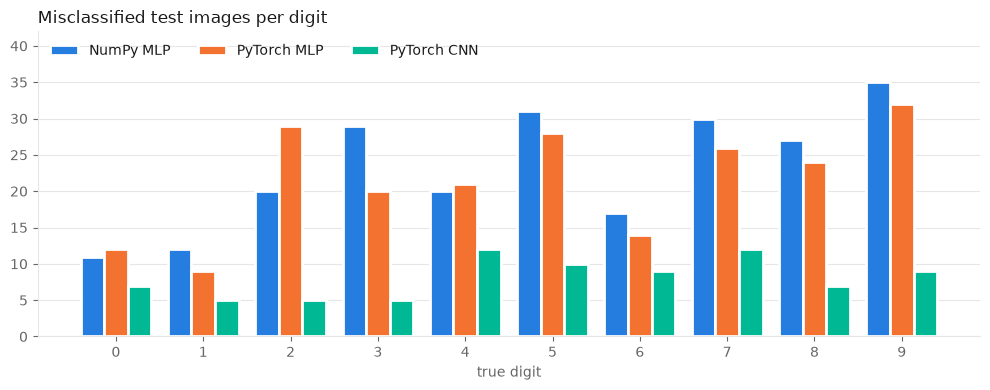

| Model | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | Total |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| NumPy MLP | 11 | 12 | 20 | 29 | 20 | 31 | 17 | 30 | 27 | 35 | 232 |
| PyTorch MLP | 12 | 9 | 29 | 20 | 21 | 28 | 14 | 26 | 24 | 32 | 215 |
| PyTorch CNN | 7 | 5 | 5 | 5 | 12 | 10 | 9 | 12 | 7 | 9 | 81 |

In [4]:
SERIES = {"NumPy MLP": "#257de0", "PyTorch MLP": "#f47230", "PyTorch CNN": "#00b894"}
digits = np.arange(10)
errors = {name: np.array([(preds[name][y_test == d] != d).sum() for d in digits]) for name in MODELS}

fig, ax = plt.subplots(figsize=(10, 4))
width = 0.27
for i, (name, color) in enumerate(SERIES.items()):
    ax.bar(digits + (i - 1) * width, errors[name], width, color=color, label=name,
           edgecolor="white", linewidth=2)  # 2px surface gap between adjacent bars
ax.set_xticks(digits)
ax.set_xlabel("true digit", color=TEXT_2)
ax.set_title("Misclassified test images per digit", loc="left", color=TEXT, fontsize=12)
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color(GRID)
ax.tick_params(colors=TEXT_2)
ax.legend(frameon=False, ncol=3, loc="upper left", bbox_to_anchor=(0, 1.0), labelcolor=TEXT)
ax.set_ylim(0, max(e.max() for e in errors.values()) * 1.2)
fig.tight_layout()
fig.savefig(ROOT / "docs/per_digit_errors.png", dpi=120, facecolor="white")
plt.show()

rows = ["| Model | " + " | ".join(map(str, digits)) + " | Total |", "|---|" + "---:|" * 11]
rows += [f"| {n} | " + " | ".join(map(str, e)) + f" | {e.sum()} |" for n, e in errors.items()]
display(Markdown("\n".join(rows)))

## Confusion matrices: which digits get mixed up

Rows are the true digit, columns the prediction. The diagonal (correct answers) is left blank
so the colour scale shows only the **mistakes**. Both panels share one scale, so they can be compared directly.

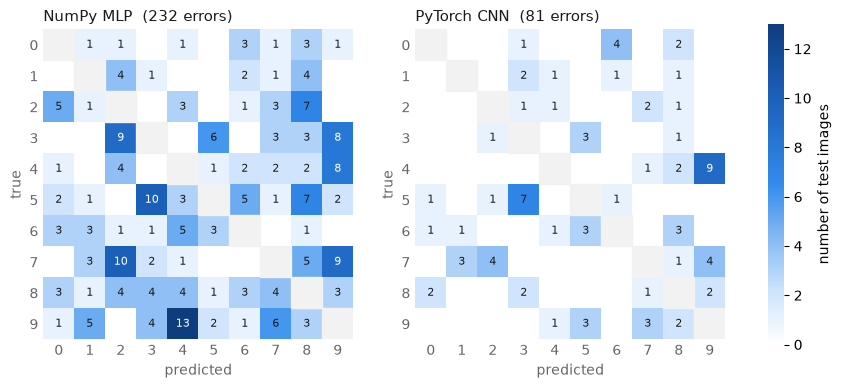

In [5]:
def confusion(y_true, y_pred):
    cm = np.zeros((10, 10), dtype=int)
    np.add.at(cm, (y_true, y_pred), 1)
    return cm

# single-hue sequential ramp (light -> dark blue)
BLUES = LinearSegmentedColormap.from_list(
    "blues", ["#ffffff", "#cce3fd", "#84b9f3", "#338ced", "#2370cd", "#1757ac", "#0e3d7e"])

shown = ["NumPy MLP", "PyTorch CNN"]
cms = {n: confusion(y_test, preds[n]) for n in shown}
vmax = max((cm - np.diag(np.diag(cm))).max() for cm in cms.values())

fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
for ax, name in zip(axes, shown):
    errs = cms[name].astype(float)
    np.fill_diagonal(errs, np.nan)
    im = ax.imshow(errs, cmap=BLUES, vmin=0, vmax=vmax)
    for t in range(10):
        for p in range(10):
            if t == p:
                ax.add_patch(plt.Rectangle((p - .5, t - .5), 1, 1, color="#f2f2f2"))
            elif errs[t, p] > 0:
                ax.text(p, t, int(errs[t, p]), ha="center", va="center", fontsize=8,
                        color="white" if errs[t, p] > vmax * 0.55 else TEXT)
    ax.set_xticks(digits)
    ax.set_yticks(digits)
    ax.set_xlabel("predicted", color=TEXT_2)
    ax.set_ylabel("true", color=TEXT_2)
    ax.set_title(f"{name}  ({int(np.nansum(errs))} errors)", loc="left", color=TEXT, fontsize=11)
    ax.tick_params(colors=TEXT_2, length=0)
    for s in ax.spines.values():
        s.set_visible(False)
cbar = fig.colorbar(im, ax=axes, shrink=0.8, label="number of test images")
cbar.outline.set_visible(False)
fig.savefig(ROOT / "docs/confusion_matrix.png", dpi=120, facecolor="white", bbox_inches="tight")
plt.show()

In [6]:
def top_confusions(cm, k=5):
    off = cm - np.diag(np.diag(cm))
    flat = np.argsort(off, axis=None)[::-1][:k]
    return [(t, p, off[t, p]) for t, p in zip(*np.unravel_index(flat, off.shape))]

rows = ["| Rank | NumPy MLP | PyTorch CNN |", "|---:|---|---|"]
for i, (a, b) in enumerate(zip(top_confusions(cms["NumPy MLP"]), top_confusions(cms["PyTorch CNN"])), 1):
    rows.append(f"| {i} | {a[0]} → {a[1]} ({a[2]}×) | {b[0]} → {b[1]} ({b[2]}×) |")
display(Markdown("**Most common mistakes** (true → predicted)\n\n" + "\n".join(rows)))

**Most common mistakes** (true → predicted)

| Rank | NumPy MLP | PyTorch CNN |
|---:|---|---|
| 1 | 9 → 4 (13×) | 4 → 9 (9×) |
| 2 | 7 → 2 (10×) | 5 → 3 (7×) |
| 3 | 5 → 3 (10×) | 0 → 6 (4×) |
| 4 | 7 → 9 (9×) | 7 → 2 (4×) |
| 5 | 3 → 2 (9×) | 7 → 9 (4×) |

## Do the models fail on the same images?

In [7]:
mlp_wrong = preds["NumPy MLP"] != y_test
cnn_wrong = preds["PyTorch CNN"] != y_test
display(Markdown(
    f"- NumPy MLP wrong: **{mlp_wrong.sum()}** images, PyTorch CNN wrong: **{cnn_wrong.sum()}**\n"
    f"- Both wrong: **{(mlp_wrong & cnn_wrong).sum()}**\n"
    f"- CNN fixes **{(mlp_wrong & ~cnn_wrong).sum()}** of the MLP's mistakes, "
    f"and gets **{(~mlp_wrong & cnn_wrong).sum()}** wrong that the MLP got right\n"
    f"- NumPy MLP vs PyTorch MLP agree on **{(preds['NumPy MLP'] == preds['PyTorch MLP']).mean():.2%}** of test images"
))

- NumPy MLP wrong: **232** images, PyTorch CNN wrong: **81**
- Both wrong: **47**
- CNN fixes **185** of the MLP's mistakes, and gets **34** wrong that the MLP got right
- NumPy MLP vs PyTorch MLP agree on **99.20%** of test images

## The CNN's most confident mistakes

Each tile: the true label, the CNN's prediction, and how confident it was.
Many of these are genuinely ambiguous, or arguably mislabelled.

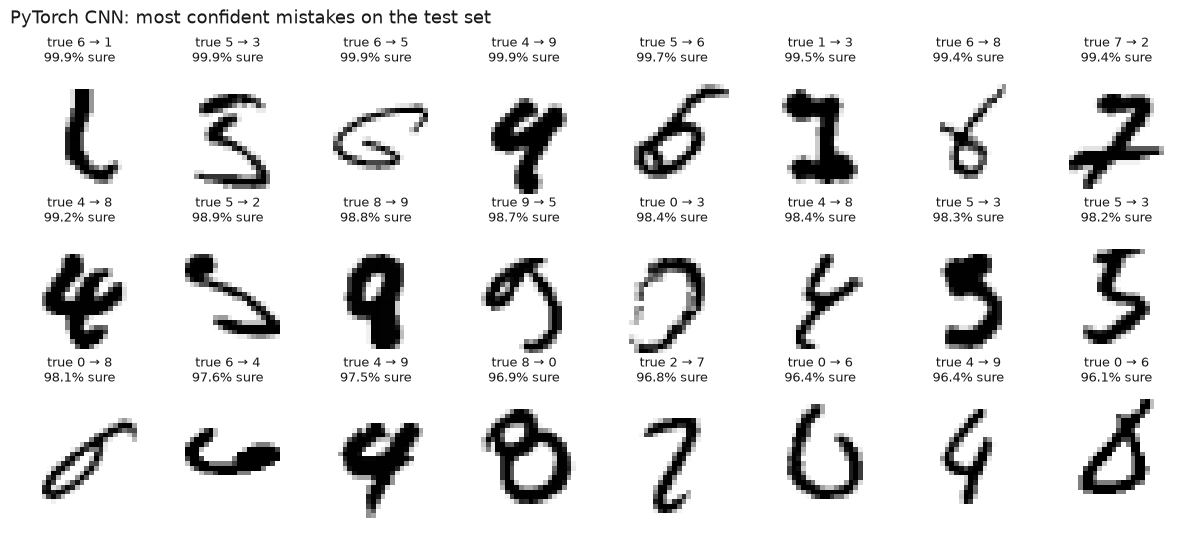

In [8]:
p_cnn = probs["PyTorch CNN"]
wrong = np.flatnonzero(cnn_wrong)
wrong = wrong[np.argsort(-p_cnn[wrong].max(1))][:24]  # most confident first

fig, axes = plt.subplots(3, 8, figsize=(12, 5.4))
for ax, i in zip(axes.flat, wrong):
    ax.imshow(X_test[i].reshape(28, 28), cmap="gray_r")
    ax.set_title(f"true {y_test[i]} → {preds['PyTorch CNN'][i]}\n{np.floor(p_cnn[i].max() * 1000) / 10:.1f}% sure",
                 fontsize=9, color=TEXT)
    ax.axis("off")
fig.suptitle("PyTorch CNN: most confident mistakes on the test set", x=0.01, ha="left",
             color=TEXT, fontsize=13)
fig.tight_layout()
fig.savefig(ROOT / "docs/misclassified.png", dpi=120, facecolor="white")
plt.show()

## Takeaways

- **The CNN makes about a third of the MLP's mistakes** (81 vs 232 test errors). It fixes 185 of the
  MLP's errors and introduces only 34 new ones. Its errors are spread thinly over all digits,
  while the MLPs struggle most with 3, 5, 7 and 9 (around 30 errors each).
- **NumPy MLP ≈ PyTorch MLP.** Same architecture, same initial weights, same data order: they agree on
  99.2% of test images. The 232 vs 215 gap comes from float32 rounding drift and a different
  early-stopping epoch, not from one implementation being better. Combined with the gradient tests,
  this confirms the hand-written backprop is correct.
- **Mistakes follow shape similarity:** 4↔9, 3↔5, 7↔2 and 7↔9 top the lists for both model types.
  These pairs differ by a single stroke (an open vs closed top, a crossbar).
- **Confidence is not correctness.** The CNN's worst mistakes are made at over 99% confidence, and
  several of those digits are ambiguous even to a person, or arguably mislabelled. Softmax outputs
  say how strongly the model prefers a class, not how likely it is to be right.
- **What could help next:** data augmentation (small shifts and rotations), batch normalisation, or an
  ensemble. Past about 99.5%, though, the remaining errors are mostly label noise.